### **Milestone 2: Data Understanding and Preparation**

# **Import Libraries**

---



In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

#**Dataset Understanding**


---




In [5]:
uploaded = files.upload()

Saving steam_top_games_2026.csv to steam_top_games_2026.csv


In [7]:
df = pd.read_csv("steam_top_games_2026.csv")

In [8]:
df.head()

,app_id,name,release_date,coming_soon,price_usd,is_free,discount_pct,developer,publisher,genres,...,estimated_owners,avg_playtime_forever,avg_playtime_2weeks,median_playtime,peak_ccu,required_age,dlc_count,achievements,short_description,header_image
0,794260,Outward Definitive Edition,"May 17, 2022",False,4.79,False,88,Nine Dots Studio,"Prime Matter, Deep Silver",RPG,...,"1,000,000 .. 2,000,000",1332,824,465,469,0,1,72,No remarkable journey is achieved without grea...,https://shared.akamai.steamstatic.com/store_it...
1,253920,Gorky 17,"Sep 27, 2013",False,9.99,False,0,Metropolis Software,TopWare Interactive,"RPG, Strategy",...,"200,000 .. 500,000",301,0,328,61,17,2,0,November 2008. NATO intelligence services repo...,https://shared.akamai.steamstatic.com/store_it...
2,613010,Secret in Story,"Jun 19, 2017",False,0.89,False,10,Naivus Luo,Naivus Luo,"Adventure, Indie",...,"2,000,000 .. 5,000,000",251,0,243,0,0,0,32,"Accompanied by beautiful piano music, you begi...",https://shared.akamai.steamstatic.com/store_it...
3,892420,懒人修仙传,"Nov 14, 2018",False,3.99,False,0,托更的修罗,托更的修罗,"Casual, Indie, RPG, Simulation",...,"200,000 .. 500,000",5786,0,9223,41,0,0,0,这是一款很&quot;休闲&quot;的文字挂机游戏，游戏小而系统完善，玩法丰富，极其耗电，...,https://shared.akamai.steamstatic.com/store_it...
4,914010,Train Station Renovation,"Oct 1, 2020",False,18.99,False,0,Live Motion Games,"Live Motion Games, Frozen Way, PlayWay S.A., F...","Casual, Indie, Simulation",...,"200,000 .. 500,000",448,0,201,16,0,1,73,"Welcome to an old, ruined train station. A pla...",https://shared.akamai.steamstatic.com/store_it...


In [9]:
df.shape

(1495, 29)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1495 entries, 0 to 1494
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   app_id                1495 non-null   int64  
 1   name                  1495 non-null   object 
 2   release_date          1488 non-null   object 
 3   coming_soon           1495 non-null   bool   
 4   price_usd             1495 non-null   float64
 5   is_free               1495 non-null   bool   
 6   discount_pct          1495 non-null   int64  
 7   developer             1487 non-null   object 
 8   publisher             1483 non-null   object 
 9   genres                1487 non-null   object 
 10  categories            1486 non-null   object 
 11  tags                  1489 non-null   object 
 12  platforms_win         1495 non-null   bool   
 13  platforms_mac         1495 non-null   bool   
 14  platforms_linux       1495 non-null   bool   
 15  metacritic_score     

In [11]:
df.isnull().sum()

,0
app_id,0
name,0
release_date,7
coming_soon,0
price_usd,0
is_free,0
discount_pct,0
developer,8
publisher,12
genres,8


In [12]:
df.describe()

,app_id,price_usd,discount_pct,metacritic_score,recommendations,positive_reviews,negative_reviews,avg_playtime_forever,avg_playtime_2weeks,median_playtime,peak_ccu,required_age,dlc_count,achievements
count,1.495000e+03,1495.000000,1495.000000,540.000000,1.495000e+03,1.495000e+03,1.495000e+03,1495.000000,1495.000000,1495.000000,1.495000e+03,1495.000000,1495.000000,1495.000000
mean,7.780528e+05,12.086763,9.412040,76.864815,2.014101e+04,2.422018e+04,3.664934e+03,1299.604682,79.339130,492.206020,1.433564e+03,1.986622,3.381271,44.121739
std,6.731430e+05,13.966433,24.572928,9.459133,1.420272e+05,2.065918e+05,3.180703e+04,3316.744797,300.504354,1656.020026,2.667776e+04,5.422555,23.636168,127.526037
min,2.000000e+01,0.000000,0.000000,24.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,2.927700e+05,0.000000,0.000000,72.000000,4.025000e+02,1.637500e+03,3.175000e+02,205.000000,0.000000,92.500000,3.000000e+00,0.000000,0.000000,0.000000
50%,5.447300e+05,8.990000,0.000000,78.000000,3.419000e+03,4.463000e+03,7.390000e+02,415.000000,0.000000,213.000000,2.700000e+01,0.000000,0.000000,27.000000
75%,1.148140e+06,19.990000,0.000000,83.000000,1.136650e+04,1.273550e+04,2.013500e+03,1139.500000,0.000000,426.500000,1.690000e+02,0.000000,2.000000,50.000000
max,3.358510e+06,149.990000,94.000000,96.000000,5.037443e+06,7.642084e+06,1.173003e+06,58347.000000,4204.000000,33638.000000,1.013936e+06,18.000000,785.000000,2975.000000


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["app_id"].duplicated().sum()

np.int64(0)

#**Data Cleaning and Feature Engineering**

---



In [15]:
cleaned_df = df.copy()

In [16]:
cleaned_df = cleaned_df.drop_duplicates(subset="app_id")

In [17]:
cleaned_df["estimated_owners"] = (
    cleaned_df["estimated_owners"]
    .str.extract(r"([\d,]+)")[0]
    .str.replace(",", "", regex=False)
    .astype(float)
)

In [18]:
cleaned_df["total_reviews"] = (
    cleaned_df["positive_reviews"] +
    cleaned_df["negative_reviews"]
)

In [19]:
cleaned_df["approval_rate"] = np.where(
    cleaned_df["total_reviews"] > 0,
    cleaned_df["positive_reviews"] /
    cleaned_df["total_reviews"],
    0
)

In [20]:
cleaned_df = cleaned_df.dropna(subset=["estimated_owners"])

In [21]:
cleaned_df.shape

(1490, 31)

In [22]:
cleaned_df[
    [
        "price_usd",
        "discount_pct",
        "avg_playtime_forever",
        "avg_playtime_2weeks",
        "peak_ccu",
        "estimated_owners",
        "total_reviews",
        "approval_rate"
    ]
].isnull().sum()

,0
price_usd,0
discount_pct,0
avg_playtime_forever,0
avg_playtime_2weeks,0
peak_ccu,0
estimated_owners,0
total_reviews,0
approval_rate,0


#**Feature Selection**

---



In [23]:
features = [
    "price_usd",
    "discount_pct",
    "avg_playtime_forever",
    "avg_playtime_2weeks",
    "peak_ccu",
    "estimated_owners",
    "total_reviews",
    "approval_rate"
]

In [24]:
X = cleaned_df[features]

In [25]:
X.head()

,price_usd,discount_pct,avg_playtime_forever,avg_playtime_2weeks,peak_ccu,estimated_owners,total_reviews,approval_rate
0,4.79,88,1332,824,469,1000000.0,28455,0.728800
1,9.99,0,301,0,61,200000.0,2027,0.797237
2,0.89,10,251,0,0,2000000.0,114,0.692982
3,3.99,0,5786,0,41,200000.0,1278,0.601721
4,18.99,0,448,0,16,200000.0,2620,0.822137


In [26]:
X.describe()

,price_usd,discount_pct,avg_playtime_forever,avg_playtime_2weeks,peak_ccu,estimated_owners,total_reviews,approval_rate
count,1490.000000,1490.000000,1490.000000,1490.000000,1.490000e+03,1.490000e+03,1.490000e+03,1490.000000
mean,12.108544,9.383221,1303.965772,79.605369,1.438374e+03,1.043289e+06,2.797869e+04,0.802624
std,13.973334,24.520522,3321.452353,300.973241,2.672238e+04,3.697444e+06,2.381397e+05,0.151912
min,0.000000,0.000000,0.000000,0.000000,0.000000e+00,2.000000e+05,0.000000e+00,0.000000
25%,0.000000,0.000000,206.250000,0.000000,3.000000e+00,2.000000e+05,2.149250e+03,0.730223
50%,8.990000,0.000000,416.000000,0.000000,2.700000e+01,5.000000e+05,5.587000e+03,0.847107
75%,19.990000,0.000000,1149.000000,0.000000,1.690000e+02,1.000000e+06,1.495500e+04,0.915787
max,149.990000,94.000000,58347.000000,4204.000000,1.013936e+06,1.000000e+08,8.815087e+06,1.000000


#**Feature Standardization**

---



In [27]:
X_transformed = X.copy()

In [28]:
log_features = [
    "avg_playtime_forever",
    "avg_playtime_2weeks",
    "peak_ccu",
    "estimated_owners",
    "total_reviews"
]

X_transformed[log_features] = np.log1p(
    X_transformed[log_features]
)

In [29]:
scaler = StandardScaler()

In [30]:
X_scaled = scaler.fit_transform(
    X_transformed
)

In [31]:
X_scaled[:5]

array([[-0.52392657,  3.20723896,  0.66678337,  2.58392407,  1.10292229,
         0.77049165,  0.91839299, -0.4861266 ],
       [-0.15166423, -0.38279657, -0.12106181, -0.5086754 ,  0.28277932,
        -0.84056652, -0.50505858, -0.03546819],
       [-0.80312332,  0.02516201, -0.21710313, -0.5086754 , -1.38825299,
         1.46433786, -2.05168779, -0.72198309],
       [-0.5811977 , -0.38279657,  1.44583174, -0.5086754 ,  0.12508923,
        -0.84056652, -0.75348491, -1.32293406],
       [ 0.49263597, -0.38279657,  0.08938034, -0.5086754 , -0.24111539,
        -0.84056652, -0.36682271,  0.12849825]])

# Milestone 3: Data Mining Implementation and Evaluation

In [32]:
silhouette_results = []

In [33]:
inertia_results = []

In [34]:
for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertia_results.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette_Score": silhouette_score(
            X_scaled, labels
        )
    })

In [35]:
silhouette_df = pd.DataFrame(inertia_results)

In [36]:
print(type(inertia_results), len(inertia_results))
print(inertia_results[:2])
print(pd.DataFrame(inertia_results).columns.tolist())

<class 'list'> 7
[{'k': 2, 'Inertia': 8744.137916397032, 'Silhouette_Score': np.float64(0.2765895969518793)}, {'k': 3, 'Inertia': 7402.909947103312, 'Silhouette_Score': np.float64(0.2065018813706317)}]
['k', 'Inertia', 'Silhouette_Score']


In [37]:
silhouette_df["Silhouette_Score"] = (
    silhouette_df["Silhouette_Score"].round(3)
)

In [38]:
silhouette_df

,k,Inertia,Silhouette_Score
0,2,8744.137916,0.277
1,3,7402.909947,0.207
2,4,6285.234920,0.240
3,5,5672.325394,0.227
4,6,5172.139998,0.209
5,7,4767.239531,0.211
6,8,4420.680771,0.221


# Milestone 4: Visualization and Interpretation

#**K-Means Clustering**

---



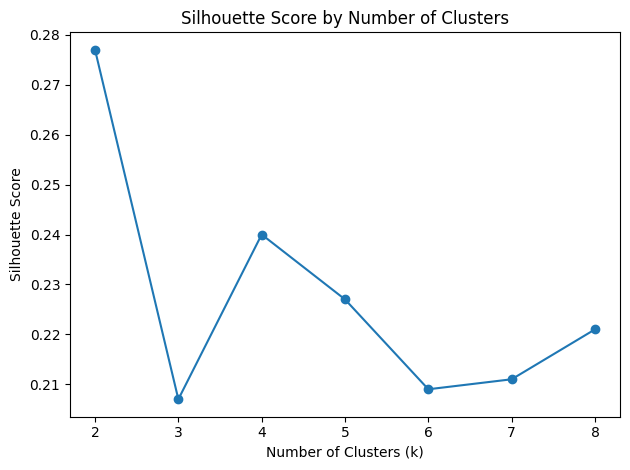

In [90]:
plt.plot(
    silhouette_df["k"],
    silhouette_df["Silhouette_Score"],
    marker="o"
)

plt.title(
    "Silhouette Score by Number of Clusters"
)

plt.xlabel(
    "Number of Clusters (k)"
)

plt.ylabel(
    "Silhouette Score"
)

plt.xticks(
    silhouette_df["k"]
)

plt.tight_layout()
plt.savefig("images/visualization_01.png", dpi=200, bbox_inches="tight")
plt.show()

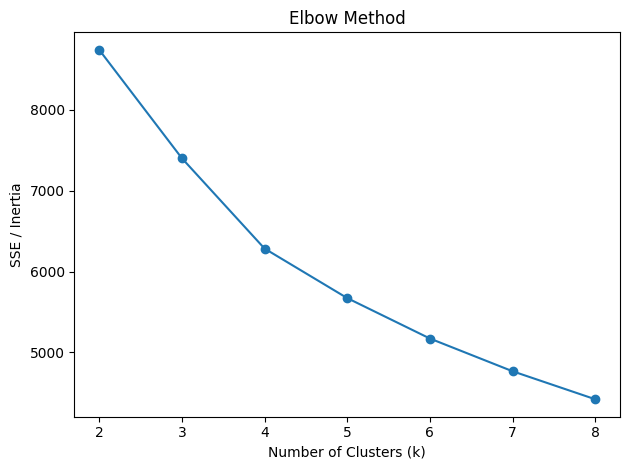

In [88]:
inertia_df = pd.DataFrame(inertia_results)

plt.plot(
    inertia_df["k"],
    inertia_df["Inertia"],
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("SSE / Inertia")

plt.xticks(range(2, 9))
plt.tight_layout()
plt.savefig("images/visualization_02.png", dpi=200, bbox_inches="tight")
plt.show()

In [42]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

In [43]:
cluster_labels = kmeans.fit_predict(X_scaled)

In [44]:
clustered_df = cleaned_df.copy()

In [45]:
clustered_df["Cluster"] = cluster_labels

In [46]:
clustered_df.head()

,app_id,name,release_date,coming_soon,price_usd,is_free,discount_pct,developer,publisher,genres,...,median_playtime,peak_ccu,required_age,dlc_count,achievements,short_description,header_image,total_reviews,approval_rate,Cluster
0,794260,Outward Definitive Edition,"May 17, 2022",False,4.79,False,88,Nine Dots Studio,"Prime Matter, Deep Silver",RPG,...,465,469,0,1,72,No remarkable journey is achieved without grea...,https://shared.akamai.steamstatic.com/store_it...,28455,0.728800,0
1,253920,Gorky 17,"Sep 27, 2013",False,9.99,False,0,Metropolis Software,TopWare Interactive,"RPG, Strategy",...,328,61,17,2,0,November 2008. NATO intelligence services repo...,https://shared.akamai.steamstatic.com/store_it...,2027,0.797237,1
2,613010,Secret in Story,"Jun 19, 2017",False,0.89,False,10,Naivus Luo,Naivus Luo,"Adventure, Indie",...,243,0,0,0,32,"Accompanied by beautiful piano music, you begi...",https://shared.akamai.steamstatic.com/store_it...,114,0.692982,1
3,892420,懒人修仙传,"Nov 14, 2018",False,3.99,False,0,托更的修罗,托更的修罗,"Casual, Indie, RPG, Simulation",...,9223,41,0,0,0,这是一款很&quot;休闲&quot;的文字挂机游戏，游戏小而系统完善，玩法丰富，极其耗电，...,https://shared.akamai.steamstatic.com/store_it...,1278,0.601721,1
4,914010,Train Station Renovation,"Oct 1, 2020",False,18.99,False,0,Live Motion Games,"Live Motion Games, Frozen Way, PlayWay S.A., F...","Casual, Indie, Simulation",...,201,16,0,1,73,"Welcome to an old, ruined train station. A pla...",https://shared.akamai.steamstatic.com/store_it...,2620,0.822137,1


In [47]:
clustered_df["Cluster"].value_counts().sort_index()

,count
Cluster,
0,470
1,1020


In [48]:
cluster_profile = (
    clustered_df
    .groupby("Cluster")[features]
    .mean()
    .round(2)
)

In [49]:
cluster_profile

,price_usd,discount_pct,avg_playtime_forever,avg_playtime_2weeks,peak_ccu,estimated_owners,total_reviews,approval_rate
Cluster,,,,,,,,
0,19.96,11.06,2639.55,239.51,4454.92,2457446.81,78052.39,0.86
1,8.49,8.61,688.55,5.92,48.40,391666.67,4905.52,0.78


In [50]:
cluster_median = (
    clustered_df
    .groupby("Cluster")[features]
    .median()
    .round(2)
)

In [51]:
cluster_median

,price_usd,discount_pct,avg_playtime_forever,avg_playtime_2weeks,peak_ccu,estimated_owners,total_reviews,approval_rate
Cluster,,,,,,,,
0,17.99,0.0,1308.5,41.5,321.5,1000000.0,23666.0,0.89
1,4.99,0.0,276.0,0.0,7.0,200000.0,3162.0,0.82


In [52]:
clustered_df.groupby("Cluster").agg(
    Game_Count=("app_id", "count"),
    Average_Price=("price_usd", "mean"),
    Average_Owners=("estimated_owners", "mean"),
    Average_Playtime=("avg_playtime_forever", "mean"),
    Average_Peak_CCU=("peak_ccu", "mean")
).round(2)

,Game_Count,Average_Price,Average_Owners,Average_Playtime,Average_Peak_CCU
Cluster,,,,,
0,470,19.96,2457446.81,2639.55,4454.92
1,1020,8.49,391666.67,688.55,48.40


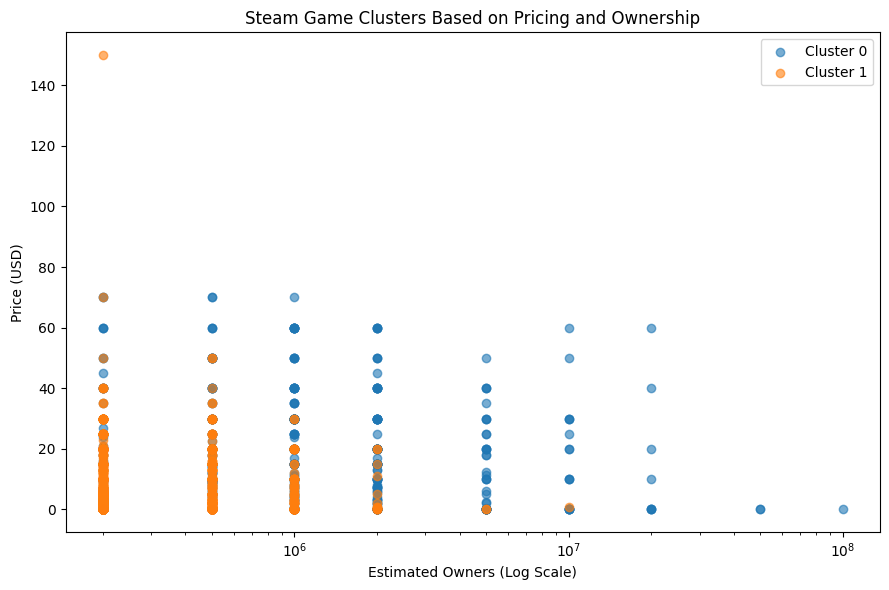

In [87]:
plt.figure(figsize=(9, 6))

for cluster in sorted(clustered_df["Cluster"].unique()):

    subset = clustered_df[
        clustered_df["Cluster"] == cluster
    ]

    plt.scatter(
        subset["estimated_owners"],
        subset["price_usd"],
        label=f"Cluster {cluster}",
        alpha=0.6
    )

plt.xscale("log")

plt.title(
    "Steam Game Clusters Based on Pricing and Ownership"
)

plt.xlabel("Estimated Owners (Log Scale)")
plt.ylabel("Price (USD)")

plt.legend()
plt.tight_layout()
plt.savefig("images/visualization_03.png", dpi=200, bbox_inches="tight")
plt.show()

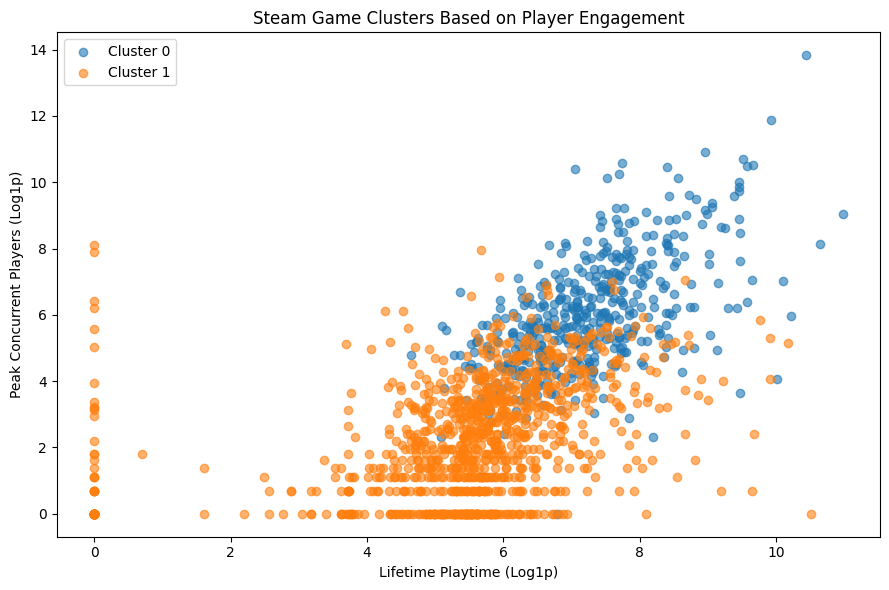

In [91]:
plt.figure(figsize=(9, 6))

for cluster in sorted(clustered_df["Cluster"].unique()):

    subset = clustered_df[
        clustered_df["Cluster"] == cluster
    ]

    plt.scatter(
        np.log1p(subset["avg_playtime_forever"]),
        np.log1p(subset["peak_ccu"]),
        label=f"Cluster {cluster}",
        alpha=0.6
    )

plt.title(
    "Steam Game Clusters Based on Player Engagement"
)

plt.xlabel("Lifetime Playtime (Log1p)")
plt.ylabel("Peak Concurrent Players (Log1p)")

plt.legend()
plt.tight_layout()
plt.savefig("images/visualization_04.png", dpi=200, bbox_inches="tight")
plt.show()

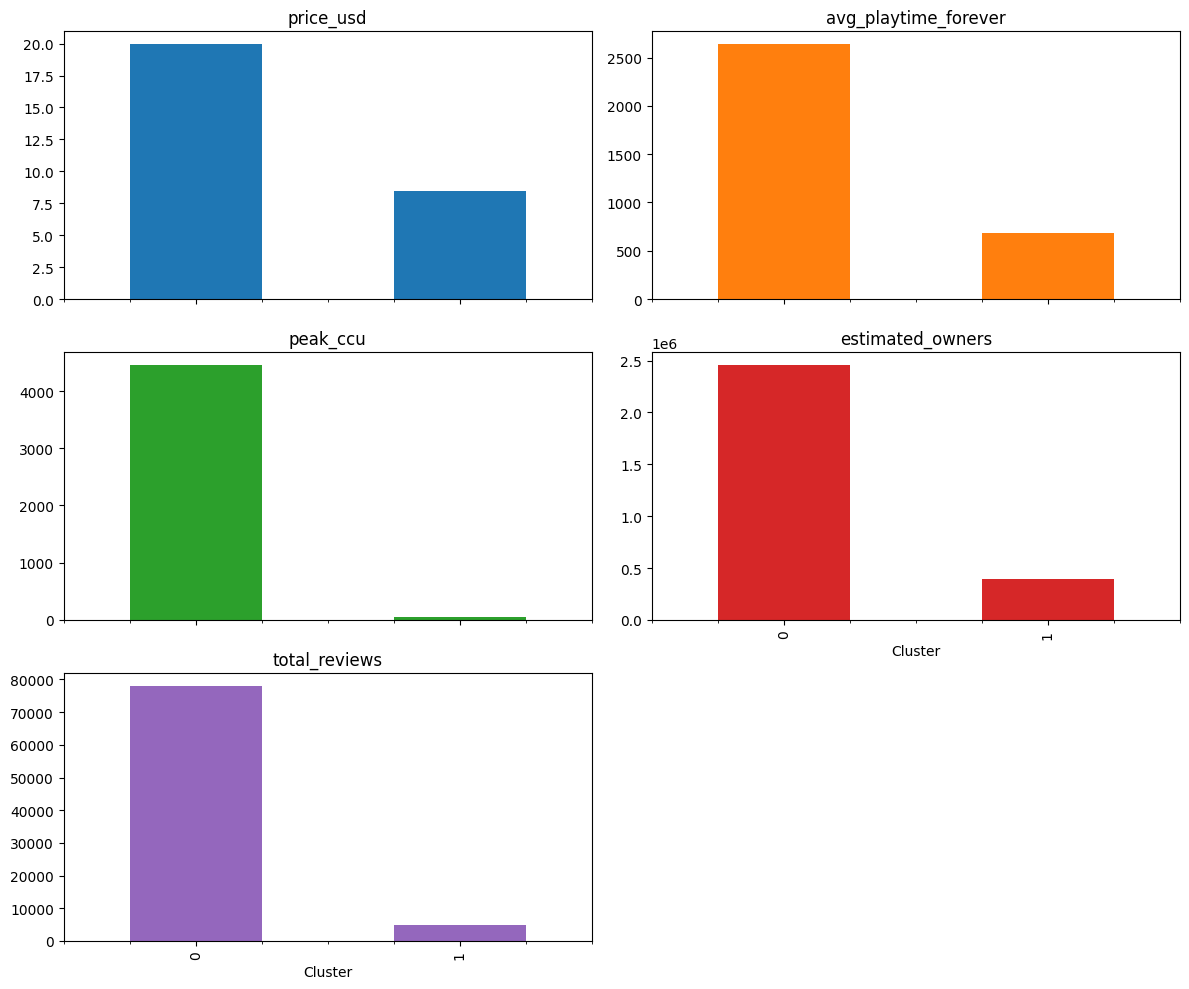

In [92]:
cluster_profile[
    [
        "price_usd",
        "avg_playtime_forever",
        "peak_ccu",
        "estimated_owners",
        "total_reviews"
    ]
].plot(
    kind="bar",
    subplots=True,
    layout=(3, 2),
    figsize=(12, 10),
    legend=False
)

plt.tight_layout()
plt.savefig("images/visualization_05.png", dpi=200, bbox_inches="tight")
plt.show()

#**Hierarchical Clustering**

---



In [56]:
hier_results = []
for n in range(2, 9):
    lbl = AgglomerativeClustering(n_clusters=n, linkage="ward").fit_predict(X_scaled)
    hier_results.append({"n_clusters": n, "Silhouette_Score": round(silhouette_score(X_scaled, lbl), 3)})

pd.DataFrame(hier_results)

,n_clusters,Silhouette_Score
0,2,0.300
1,3,0.169
2,4,0.193
3,5,0.191
4,6,0.186
5,7,0.198
6,8,0.160


In [57]:
hierarchical = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(
    X_scaled
)

In [58]:
hierarchical_score = silhouette_score(
    X_scaled,
    hierarchical_labels
)

print("Hierarchical Silhouette Score:",
      hierarchical_score)

Hierarchical Silhouette Score: 0.29983347111546277


#**DBSCAN**

---



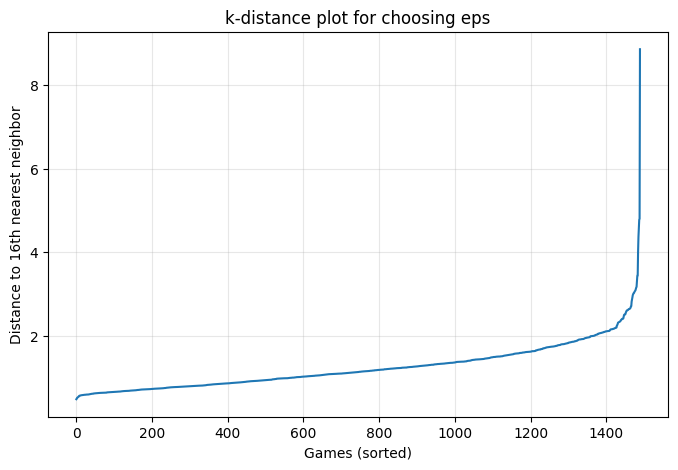

In [93]:
k = 16
nn = NearestNeighbors(n_neighbors=k).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_dist)
plt.xlabel("Games (sorted)")
plt.ylabel(f"Distance to {k}th nearest neighbor")
plt.title("k-distance plot for choosing eps")
plt.grid(alpha=0.3)
plt.savefig("images/visualization_06.png", dpi=200, bbox_inches="tight")
plt.show()

In [60]:
grid_results = []

for min_samples in [5, 10, 16, 20]:
    for eps in np.arange(0.5, 2.51, 0.25):

        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)

        n_clusters = len(set(labels) - {-1})
        n_noise = int((labels == -1).sum())
        mask = labels != -1

        if n_clusters >= 2 and mask.sum() > n_clusters:
            sil = silhouette_score(X_scaled[mask], labels[mask])
            largest_pct = pd.Series(labels[mask]).value_counts(normalize=True).iloc[0] * 100
        else:
            sil = np.nan
            largest_pct = np.nan

        grid_results.append({
            "eps": round(eps, 2),
            "min_samples": min_samples,
            "Clusters": n_clusters,
            "Noise_Points": n_noise,
            "Noise_Pct": round(n_noise / len(X_scaled) * 100, 1),
            "Largest_Cluster_Pct": round(largest_pct, 1),
            "Silhouette_No_Noise": round(sil, 3) if not np.isnan(sil) else np.nan
        })

dbscan_grid = pd.DataFrame(grid_results)

dbscan_grid[(dbscan_grid["Clusters"] >= 2) & (dbscan_grid["Noise_Pct"] <= 30)] \
    .sort_values("Silhouette_No_Noise", ascending=False).head(10)

,eps,min_samples,Clusters,Noise_Points,Noise_Pct,Largest_Cluster_Pct,Silhouette_No_Noise
30,1.25,20,2,385,25.8,90.5,0.347
21,1.25,16,3,327,21.9,88.5,0.327
22,1.50,16,2,148,9.9,98.8,0.296
32,1.75,20,2,66,4.4,98.9,0.266
13,1.50,10,2,96,6.4,98.4,0.264
12,1.25,10,3,244,16.4,89.8,0.263
2,1.00,5,9,343,23.0,84.4,0.119
3,1.25,5,4,157,10.5,88.7,0.075


In [61]:
dbscan = DBSCAN(
    eps=1.25,
    min_samples=16
)

dbscan_labels = dbscan.fit_predict(X_scaled)

In [62]:
dbscan_sizes = pd.Series(dbscan_labels).value_counts().sort_index()
print(dbscan_sizes)

-1     327
 0    1029
 1     110
 2      24
Name: count, dtype: int64


In [63]:
unique_labels = set(dbscan_labels)

valid_clusters = unique_labels - {-1}

if len(valid_clusters) >= 2:

    mask = dbscan_labels != -1

    score = silhouette_score(
        X_scaled[mask],
        dbscan_labels[mask]
    )

    print("DBSCAN Silhouette Score:", score)

else:
    print("Silhouette Score cannot be calculated.")

DBSCAN Silhouette Score: 0.3268181033742334


#**Dashboard Preparation (PowerBI)**

---



In [64]:
dashboard_df = cleaned_df.copy()
dashboard_df["KMeans_Cluster"] = cluster_labels
dashboard_df["Hierarchical_Cluster"] = hierarchical_labels
dashboard_df["DBSCAN_Cluster"] = dbscan_labels

In [65]:
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_scaled)

print("Explained variance:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

assert len(dashboard_df) == len(pca_coords)

dashboard_df["PC1"] = pca_coords[:, 0]
dashboard_df["PC2"] = pca_coords[:, 1]

Explained variance: [0.432 0.145] | total: 0.577


In [66]:
dashboard_columns = [
    "app_id",
    "name",
    "price_usd",
    "discount_pct",
    "avg_playtime_forever",
    "avg_playtime_2weeks",
    "peak_ccu",
    "estimated_owners",
    "total_reviews",
    "approval_rate",
    "KMeans_Cluster",
    "Hierarchical_Cluster",
    "DBSCAN_Cluster",
    "PC1",
    "PC2"
]

In [67]:
dashboard_df["KMeans_Cluster"] = (
    dashboard_df["KMeans_Cluster"]
    .apply(lambda x: f"Cluster {x}")
)

dashboard_df["Hierarchical_Cluster"] = (
    dashboard_df["Hierarchical_Cluster"]
    .apply(lambda x: f"Cluster {x}")
)

dashboard_df["DBSCAN_Cluster"] = (
    dashboard_df["DBSCAN_Cluster"]
    .apply(lambda x: "Noise" if x == -1 else f"Cluster {x}")
)

In [68]:
dashboard_df["avg_playtime_forever"] = dashboard_df["avg_playtime_forever"] / 60
dashboard_df["avg_playtime_2weeks"] = dashboard_df["avg_playtime_2weeks"] / 60

In [69]:
dashboard_df = dashboard_df[
    [col for col in dashboard_columns if col in dashboard_df.columns]
]

In [70]:
dashboard_df.to_csv(
    "steam_dashboard_data.csv",
    index=False
)

files.download("steam_dashboard_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [71]:
comparison_dashboard = dashboard_df.melt(
    id_vars=["app_id"],
    value_vars=[
        "KMeans_Cluster",
        "Hierarchical_Cluster",
        "DBSCAN_Cluster"
    ],
    var_name="Algorithm",
    value_name="Cluster"
)

comparison_dashboard["Algorithm"] = comparison_dashboard["Algorithm"].replace({
    "KMeans_Cluster": "K-Means",
    "Hierarchical_Cluster": "Hierarchical",
    "DBSCAN_Cluster": "DBSCAN"
})

comparison_dashboard.to_csv("steam_cluster_comparison.csv", index=False)
files.download("steam_cluster_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [72]:
kmeans_n_clusters = len(set(cluster_labels))
kmeans_silhouette = silhouette_score(X_scaled, cluster_labels)
kmeans_inertia = kmeans.inertia_

hier_n_clusters = len(set(hierarchical_labels))
hier_silhouette = hierarchical_score  # from cell 61

dbscan_n_clusters = len(set(dbscan_labels) - {-1})
dbscan_noise = int((dbscan_labels == -1).sum())
mask = dbscan_labels != -1

if dbscan_n_clusters >= 2 and mask.sum() > dbscan_n_clusters:
    dbscan_silhouette = silhouette_score(X_scaled[mask], dbscan_labels[mask])
else:
    dbscan_silhouette = np.nan

algorithm_evaluation = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical", "DBSCAN"],
    "Number_of_Clusters": [kmeans_n_clusters, hier_n_clusters, dbscan_n_clusters],
    "Noise_Points": [0, 0, dbscan_noise],
    "Silhouette_Score": [kmeans_silhouette, hier_silhouette, dbscan_silhouette],
    "Inertia": [kmeans_inertia, np.nan, np.nan]
})

algorithm_evaluation["Silhouette_Score"] = algorithm_evaluation["Silhouette_Score"].round(3)
algorithm_evaluation["Inertia"] = algorithm_evaluation["Inertia"].round(2)

display(algorithm_evaluation)

,Algorithm,Number_of_Clusters,Noise_Points,Silhouette_Score,Inertia
0,K-Means,2,0,0.277,8744.14
1,Hierarchical,2,0,0.300,NaN
2,DBSCAN,3,327,0.327,NaN


In [73]:
algorithm_evaluation.to_csv("steam_algorithm_evaluation.csv", index=False)
files.download("steam_algorithm_evaluation.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [94]:
!zip -r images.zip images
files.download("images.zip")

updating: images/ (stored 0%)
updating: images/visualization_02.png (deflated 13%)
updating: images/visualization_05.png (deflated 33%)
updating: images/visualization_03.png (deflated 15%)
updating: images/visualization_04.png (deflated 5%)
updating: images/visualization_01.png (deflated 11%)
updating: images/visualization_06.png (deflated 16%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>